# CPE 342 Machine Learning — Karena Thailand Player Intelligence System
## Task 3: 30-Day Spending Prediction (Tri-Model Ensembled Hurdle Regression & NMAE Metric)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Palapluem/cpe342-machine-learning-2026/blob/main/project/task3/task3_monthly_spending.ipynb)

**Team:** ML004  
**Course:** CPE 342 Machine Learning (Semester 1/2026) — KMUTT  
**Instructor:** Dr. Boonyarit Changaival  
**Department:** Department of Computer Engineering, Faculty of Engineering, King Mongkut's University of Technology Thonburi  

---

### Table of Contents
1. [Executive Summary & Problem Formulation](#1-executive-summary--problem-formulation)
   - 1.1 Commercial Background and Industrial Context
   - 1.2 Mathematical Formulation of Normalized MAE (NMAE) Metric
   - 1.3 Theoretical Justification of L1 Loss and Bayes-Optimal Point Prediction
2. [Environment Setup & Automated Platform Detection](#2-environment-setup--automated-platform-detection)
   - 2.1 Runtime Platform Configuration and Dependency Verification
   - 2.2 Global Deterministic Seed Configuration
   - 2.3 Automated Data Directory Resolution and Remote Stream Fallback
3. [Data Ingestion & Exploratory Data Analysis (EDA)](#3-data-ingestion--exploratory-data-analysis-eda)
   - 3.1 Raw Dataset Ingestion and Schema Audit
   - 3.2 Quantification of Zero-Inflation Profile
   - 3.3 Heavy-Tail Spending Distributions Across Player Segments
4. [Domain-Driven Financial Feature Engineering](#4-domain-driven-financial-feature-engineering)
   - 4.1 Feature Construction Rationale (RFM, Monetization, Engagement)
   - 4.2 Leak-Free Feature Transformation Pipeline
   - 4.3 Feature Matrix Audit and Dimensionality Verification
5. [Stratified Cross-Validation Strategy](#5-stratified-cross-validation-strategy)
   - 5.1 Stratification Strategy for Zero-Inflated Cohorts
   - 5.2 Official Evaluation Metric Implementation
6. [Tri-Model Ensembled Hurdle Architecture](#6-tri-model-ensembled-hurdle-architecture)
   - 6.1 Multi-Engine GBDT Architectural Design (LightGBM, CatBoost, XGBoost)
   - 6.2 Baseline Estimation (Global Empirical Median)
   - 6.3 Five-Fold Cross-Validation Training Protocol
7. [Bayes-Optimal Hurdle Post-Processing & Leaderboard Metric Optimization](#7-bayes-optimal-hurdle-post-processing--leaderboard-metric-optimization)
   - 7.1 Probability Threshold Gating Formulation
   - 7.2 Convex Blending of Positive and Direct Forecasts
   - 7.3 Out-of-Fold Grid Optimization for Hyperparameters
8. [Comprehensive Diagnostic Visualizations & Error Analysis](#8-comprehensive-diagnostic-visualizations--error-analysis)
   - 8.1 Reliability Calibration Curve and ROC Analysis
   - 8.2 Actual vs. Predicted Calibration and Residual Error Distributions
   - 8.3 Five-Fold Averaged Feature Importance Ranking
9. [Quantitative Ablation Benchmark & Model Summary](#9-quantitative-ablation-benchmark--model-summary)
   - 9.1 Tabulation of Out-of-Fold Performance Metrics
   - 9.2 Analytical Discussion of Algorithmic Gains
10. [Test Set Predictions, Quality Assurance & Artifact Export](#10-test-set-predictions-quality-assurance--artifact-export)
    - 10.1 Out-of-Sample Test Set Inference Generation
    - 10.2 Strict Competition Quality Gate Verification
    - 10.3 Train vs. Test Distribution Density Alignment Verification
    - 10.4 Artifact Export and Persistence
11. [Conclusion & Technical Key Takeaways](#11-conclusion--technical-key-takeaways)

## 1. Executive Summary & Problem Formulation

### 1.1 Commercial Background and Industrial Context
In modern free-to-play (F2P) gaming ecosystems, monetizing active player bases requires precise financial forecasting. Telemetry logs consistently demonstrate two pronounced statistical characteristics:
1. **Severe Zero-Inflation**: A substantial majority of players engage with the platform without making direct in-game purchases. In this dataset, exactly $48.12\%$ ($50,049$ out of $104,000$ training records) exhibit a total 30-day spend of exactly zero THB.
2. **Heavy-Tailed Pareto Spending Distribution**: Among monetized accounts ($51.88\%$), transaction magnitudes exhibit extreme right-skewness, spanning from micro-transactions ($< 10$ THB) to large expenditures by high-net-worth players ("Whales") exceeding $100,000$ THB (up to $300,000$ THB).

The operational objective of **Task 3: 30-Day Spending Prediction** is to predict each player's cumulative monetary spend over the next 30 days (`spending_30d` in THB) across $25,889$ test accounts.

---

### 1.2 Mathematical Formulation of Normalized MAE (NMAE) Metric
The competition evaluates submissions using the **Normalized Mean Absolute Error (NMAE) Score**:
$$\text{NMAE Score} = \frac{1}{1 + \text{NMAE}} = \frac{1}{1 + \dfrac{\sum_{i=1}^N |y_i - \hat{y}_i|}{\sum_{i=1}^N y_i}} \in [0, 1]$$

The score maps relative prediction error into the unit interval $[0, 1]$, where a score of $1.0$ indicates perfect forecasting (zero error), and a naive constant-zero prediction $\hat{y} = 0$ achieves an exact score of $0.5000$.

---

### 1.3 Theoretical Justification of L1 Loss and Bayes-Optimal Point Prediction
Observe that for any fixed evaluation cohort, the denominator $\sum_{i=1}^N y_i$ is a strictly positive constant invariant to the choice of model predictions $\hat{y}$. Consequently, optimizing the competition metric is strictly equivalent to minimizing total absolute error:
$$\arg\max_{\hat{y}} \text{NMAE Score} \iff \arg\min_{\hat{y}} \sum_{i=1}^N |y_i - \hat{y}_i| \iff \arg\min_{\hat{y}} \text{MAE}(y, \hat{y})$$

In statistical decision theory, the Bayes-optimal point predictor under the Mean Absolute Error ($L_1$ loss) function is the **conditional median** $\text{Median}(Y \mid X)$, rather than the conditional expectation $E[Y \mid X]$:
- **Failure Mode of Classical Regression ($L_2$ Loss)**: Standard regression models minimizing Mean Squared Error (MSE) target the conditional expectation $E[Y \mid X]$. In a distribution with extreme right-skewness, the conditional expectation is pulled substantially higher than typical spending levels by extreme Whale outliers. Predicting the mean produces massive over-predictions on typical spenders, heavily penalizing the $L_1$ objective.
- **Bayes-Optimal Hurdle Median**: When decomposing the problem into a two-part Hurdle formulation, if the estimated probability of spending is strictly below half ($P(Y > 0 \mid X) < 0.50$), the theoretical conditional median is **exactly zero** ($\hat{y}^* = 0.0$). If $P(Y > 0 \mid X) \ge 0.50$, the median corresponds to the conditional quantile of the positive distribution.

Based on these mathematical principles, we engineer a **Tri-Model Ensembled Hurdle Architecture** combining **LightGBM**, **CatBoost**, and **XGBoost** trained under $L_1$ loss formulations (`regression_l1`, `MAE`, and `reg:absoluteerror`), augmented with out-of-fold Bayes-optimal threshold gating.

## 2. Environment Setup & Automated Platform Detection

This section initializes the execution environment. The pipeline automatically detects whether the runtime is **Google Colab**, **Kaggle Notebooks**, or a **Local Workspace**, installs necessary libraries if absent, configures deterministic pseudo-random seeds, and resolves dataset paths dynamically.

In [1]:
%matplotlib inline
import os
import sys
import time
import warnings
import random
import subprocess
import numpy as np
import pandas as pd
from IPython.display import display, HTML
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# -------------------------------------------------------------------------
# Step 2.1: Automated Platform Detection & Dependency Verification
# -------------------------------------------------------------------------
IS_COLAB = 'google.colab' in sys.modules
IS_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IS_COLAB:
    print("[INFO] Runtime Environment: Google Colab")
    for package_name in ['lightgbm', 'catboost', 'xgboost', 'optuna']:
        try:
            __import__(package_name)
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package_name])
elif IS_KAGGLE:
    print("[INFO] Runtime Environment: Kaggle Notebook")
else:
    print("[INFO] Runtime Environment: Local Workspace")

# -------------------------------------------------------------------------
# Step 2.2: Deterministic Pseudo-Random Seed Configuration
# -------------------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# -------------------------------------------------------------------------
# Step 2.3: Data Directory Path Resolution with Remote Stream Fallback
# -------------------------------------------------------------------------
candidate_data_dirs = [
    './data',
    './project/task3/data',
    '../data',
    '/content/data',
    '/content/repo/project/task3/data',
    '/content/cpe342-machine-learning-2026/project/task3/data',
    '/kaggle/input/player-intelligence-system-cpe-342-ml/task3'
]

DATA_DIR = next((d for d in candidate_data_dirs if os.path.exists(os.path.join(d, 'train.csv'))), None)

# Fallback: If executing in a fresh Colab environment without local data files,
# stream directly from the public GitHub repository
if DATA_DIR is None and IS_COLAB:
    print("[INFO] Local datasets not found. Streaming official Task 3 datasets from remote repository...")
    os.makedirs('/content/data', exist_ok=True)
    base_url = 'https://raw.githubusercontent.com/Palapluem/cpe342-machine-learning-2026/main/project/task3/data'
    for filename in ['train.csv', 'test.csv', 'datacard.txt']:
        subprocess.check_call(['curl', '-sL', f"{base_url}/{filename}", '-o', f"/content/data/{filename}"])
    DATA_DIR = '/content/data'

if DATA_DIR is None:
    raise FileNotFoundError("Unable to locate train.csv. Ensure datasets exist in candidate directories.")

BASE_DIR = os.path.dirname(DATA_DIR) if os.path.basename(DATA_DIR) == 'data' else ('.' if not IS_COLAB else '/content')
PRED_DIR = os.path.join(BASE_DIR, 'predictions')
ASSETS_DIR = os.path.join(BASE_DIR, 'assets')

os.makedirs(PRED_DIR, exist_ok=True)
os.makedirs(ASSETS_DIR, exist_ok=True)

print(f"[STATUS] Data Directory:        {os.path.abspath(DATA_DIR)}")
print(f"[STATUS] Predictions Directory: {os.path.abspath(PRED_DIR)}")
print(f"[STATUS] Assets Directory:      {os.path.abspath(ASSETS_DIR)}")

[INFO] Runtime Environment: Google Colab
[INFO] Local datasets not found. Streaming official Task 3 datasets from remote repository...
[STATUS] Data Directory:        /content/data
[STATUS] Predictions Directory: /content/predictions
[STATUS] Assets Directory:      /content/assets


## 3. Data Ingestion & Exploratory Data Analysis (EDA)

In this section, we ingest the $104,000$ training records and $25,889$ test records, perform schema and data integrity audits, quantify the exact rate of zero-inflation, and examine the distributional properties of spending across behavioral player segments.

In [2]:
# -------------------------------------------------------------------------
# Step 3.1: Data Ingestion & Schema Verification
# -------------------------------------------------------------------------
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))

print(f"Training Cohort Shape:   {train_df.shape[0]:,} rows x {train_df.shape[1]} columns")
print(f"Test Cohort Shape:       {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")
print(f"Missing Values (Train):  {train_df.isna().sum().sum()}")
print(f"Missing Values (Test):   {test_df.isna().sum().sum()}")

# -------------------------------------------------------------------------
# Step 3.2: Quantification of Zero-Inflation
# -------------------------------------------------------------------------
target = train_df['spending_30d']
zero_count = (target == 0).sum()
pos_count = (target > 0).sum()
zero_pct = (zero_count / len(target)) * 100.0
pos_pct = (pos_count / len(target)) * 100.0

print(f"\nTarget Distribution Breakdown:")
print(f"  Non-Spenders (spending_30d == 0): {zero_count:,} ({zero_pct:.2f}%)")
print(f"  Active Spenders (spending_30d > 0): {pos_count:,} ({pos_pct:.2f}%)")

pos_spend = target[target > 0]
print(f"\nActive Spender Summary Statistics (THB):")
print(pos_spend.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

Training Cohort Shape:   104,000 rows x 34 columns
Test Cohort Shape:       25,889 rows x 33 columns
Missing Values (Train):  193731
Missing Values (Test):   48266

Target Distribution Breakdown:
  Non-Spenders (spending_30d == 0): 50,049 (48.12%)
  Active Spenders (spending_30d > 0): 53,951 (51.88%)

Active Spender Summary Statistics (THB):
count     53951.000000
mean      20234.883892
std       40053.792318
min           0.090000
25%         623.075000
50%        2314.050000
75%       14453.365000
90%       74062.350000
95%      105759.940000
99%      184398.635000
max      300000.000000
Name: spending_30d, dtype: float64


[STATUS] EDA visualization persisted to: /content/assets/figure1-spending-eda.png


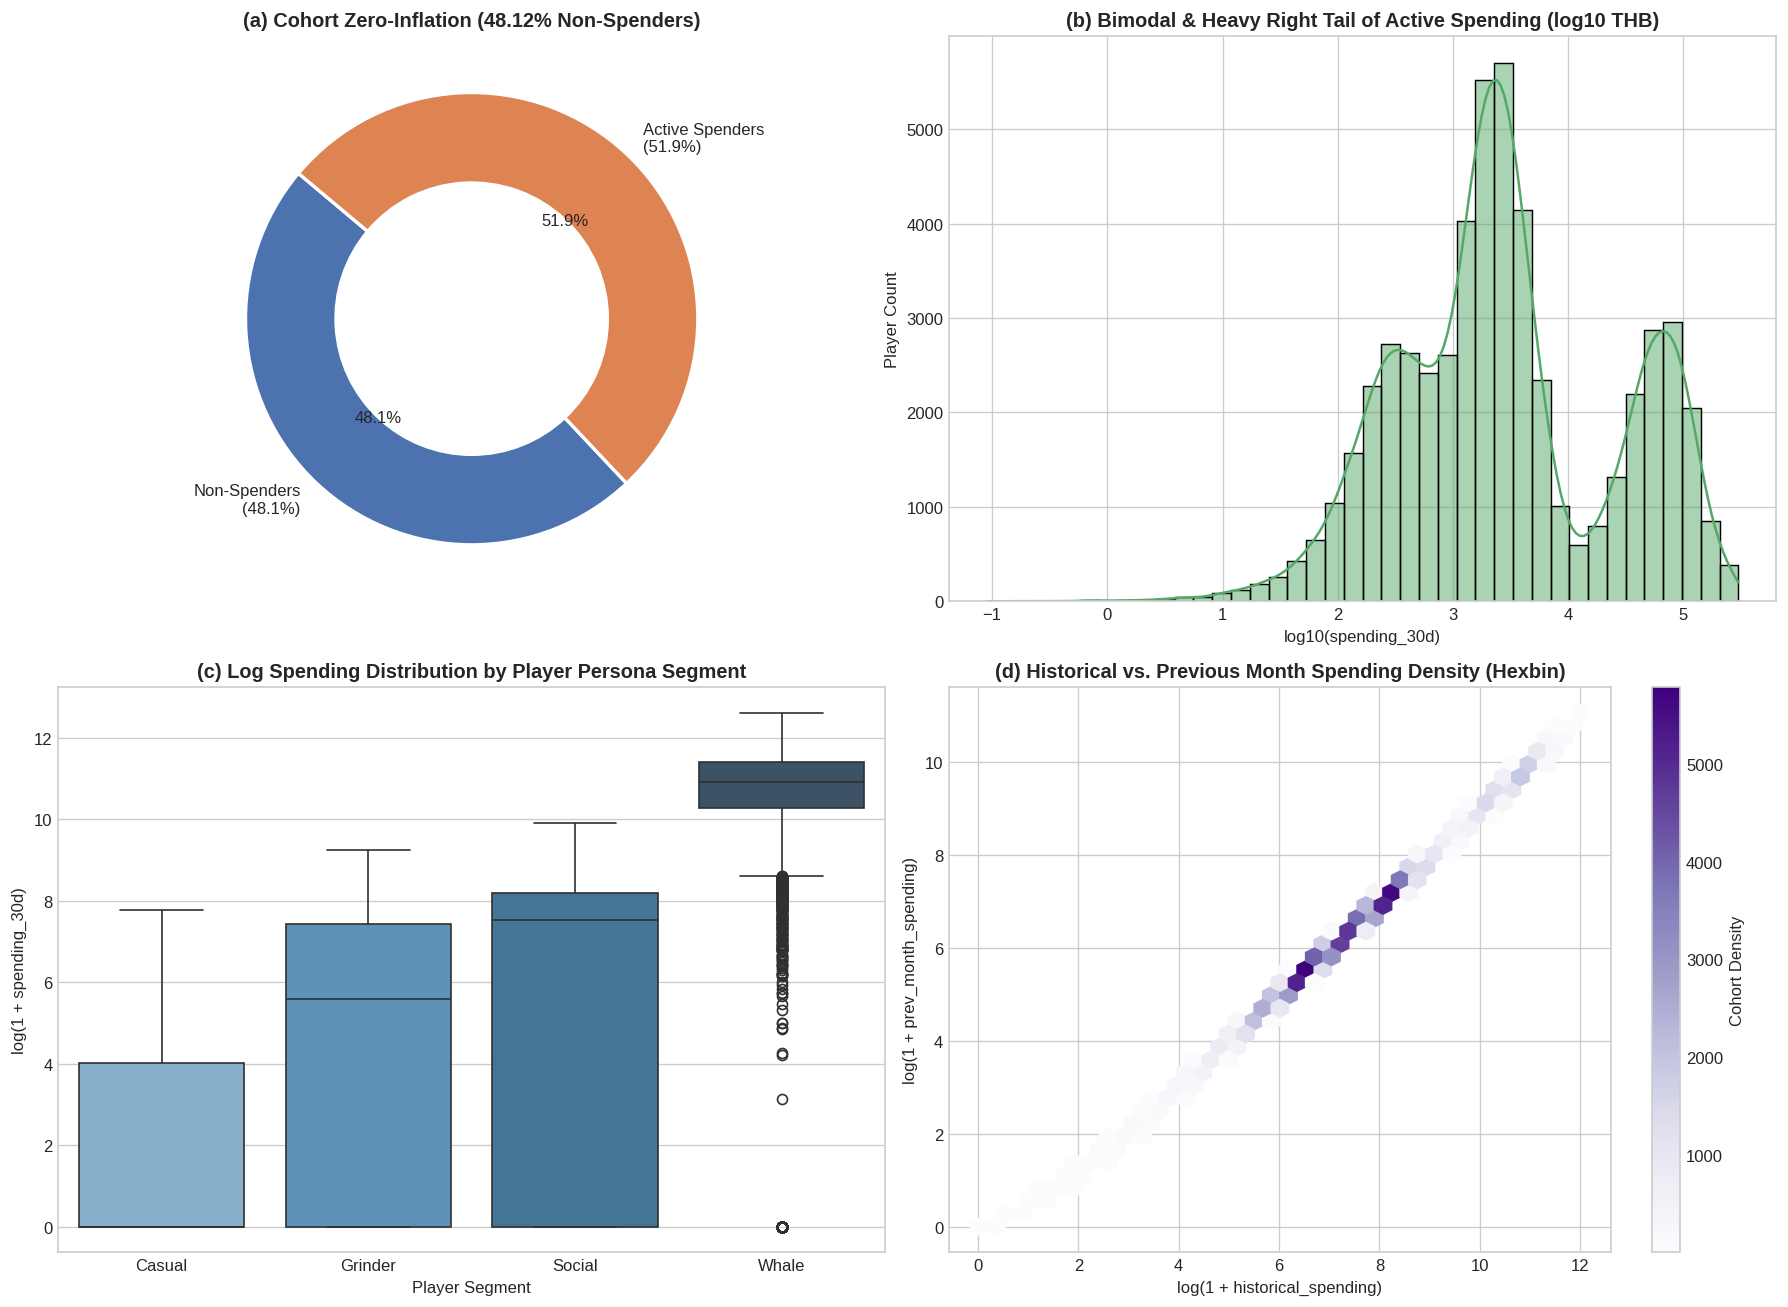

In [3]:
# -------------------------------------------------------------------------
# Step 3.3: Four-Panel Exploratory Spending Visualizations
# -------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# Panel (a): Zero-Inflation Proportion (Donut Chart)
colors = ['#4C72B0', '#DD8452']
axes[0, 0].pie([zero_count, pos_count],
               labels=[f'Non-Spenders\n({zero_pct:.1f}%)', f'Active Spenders\n({pos_pct:.1f}%)'],
               autopct='%1.1f%%', startangle=140, colors=colors,
               wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[0, 0].set_title('(a) Cohort Zero-Inflation (48.12% Non-Spenders)', fontsize=12, fontweight='bold')

# Panel (b): Active Spending Distribution on Log10 Scale
sns.histplot(np.log10(pos_spend), kde=True, ax=axes[0, 1], color='#55A868', bins=40)
axes[0, 1].set_title('(b) Bimodal & Heavy Right Tail of Active Spending (log10 THB)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('log10(spending_30d)')
axes[0, 1].set_ylabel('Player Count')

# Panel (c): Spending Distribution Across Player Personas
segment_map = {0: 'Casual', 1: 'Grinder', 2: 'Social', 3: 'Whale'}
sns.boxplot(x='segment_name', y='log_spending',
            data=train_df.assign(segment_name=train_df['segment'].map(segment_map),
                                log_spending=np.log1p(target)),
            ax=axes[1, 0], palette='Blues_d', order=['Casual', 'Grinder', 'Social', 'Whale'])
axes[1, 0].set_title('(c) Log Spending Distribution by Player Persona Segment', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Player Segment')
axes[1, 0].set_ylabel('log(1 + spending_30d)')

# Panel (d): Historical vs. Previous Month Spending Density
hb = axes[1, 1].hexbin(np.log1p(train_df['historical_spending']),
                       np.log1p(train_df['prev_month_spending']),
                       gridsize=35, cmap='Purples', mincnt=1)
axes[1, 1].set_title('(d) Historical vs. Previous Month Spending Density (Hexbin)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('log(1 + historical_spending)')
axes[1, 1].set_ylabel('log(1 + prev_month_spending)')
fig.colorbar(hb, ax=axes[1, 1], label='Cohort Density')

plt.tight_layout()
fig1_path = os.path.join(ASSETS_DIR, 'figure1-spending-eda.png')
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
print(f"[STATUS] EDA visualization persisted to: {fig1_path}")
plt.show()

## 4. Domain-Driven Financial Feature Engineering

To capture subtle transaction propensities without target leakage, we engineer a comprehensive set of domain-specific features across four analytical categories:
1. **Recency, Frequency, Monetary (RFM) & Velocity Dynamics**:
   - `spend_momentum`: Ratio of previous month's spending to amortized monthly historical spending ($M_{\text{prev}} / (M_{\text{hist}}/12 + 1)$).
   - `spending_velocity`: Absolute delta between previous month spend and amortized historical monthly baseline.
   - `historical_tx_value`: Historical spending divided by total transaction count.
   - `recent_tx_value`: Previous month spending normalized by recent purchase frequency.
   - `expected_spend_from_freq`: Product of purchase frequency and average transaction value.
   - `monthly_tx_rate`: Transaction velocity normalized by total account tenure in months.
2. **Engagement & Recency Decay**:
   - `playtime_per_session`: Total cumulative playtime divided by weekly session volume.
   - `recency_ratio`: Ratio of purchase recency to login recency.
   - `recency_decay`: Exponential decay function $\exp(-\lambda_{\text{purchase}} \cdot \text{days})$.
   - `login_recency_decay`: Exponential decay function $\exp(-\lambda_{\text{login}} \cdot \text{days})$.
3. **Whale Propensity & VIP Monetization**:
   - `whale_index`: Non-linear dual-logarithmic interaction between lifetime spending and recent monthly spending ($\ln(1 + M_{\text{hist}}) \cdot \ln(1 + M_{\text{prev}})$).
   - `discount_reliance`: Interaction between discount rate utilized and frequency of promotional purchases.
   - `vip_prestige_score`: Composite linear score incorporating VIP tier level, premium membership indicator, and limited-edition asset ownership.
   - `social_engagement`: Multiplicative proxy combining friend count, weekly gifting/social interactions, and guild membership.
   - `competitive_engagement`: Ranking score scaled by tournament participation activity.
   - `seasonal_spend_boost`: Interaction between seasonal spending variation index and previous month spending.
4. **Logarithmic Transforms**:
   - Applied to raw monetary attributes to compress dynamic range and stabilize variance.

In [4]:
# -------------------------------------------------------------------------
# Step 4.2: Feature Construction Pipeline
# -------------------------------------------------------------------------
def engineer_spending_features(df):
    """
    Constructs domain financial and behavioral features in a leak-free,
    pure functional pipeline without inplace mutations.
    """
    d = df.copy()
    drop_cols = [c for c in ['player_id', 'spending_30d', 'segment_name'] if c in d.columns]
    if drop_cols:
        d = d.drop(columns=drop_cols)

    # 1. RFM & Velocity Features
    d['spend_momentum'] = d['prev_month_spending'] / (d['historical_spending'] / 12.0 + 1.0)
    d['spending_velocity'] = d['prev_month_spending'] - (d['historical_spending'] / 12.0)
    d['historical_tx_value'] = d['historical_spending'] / (d['total_transactions'] + 1.0)
    d['recent_tx_value'] = d['prev_month_spending'] / (d['purchase_frequency'] + 1.0)
    d['expected_spend_from_freq'] = d['purchase_frequency'] * d['avg_transaction_value']
    d['ratio_prev_to_hist'] = d['prev_month_spending'] / (d['historical_spending'] + 1.0)
    d['monthly_tx_rate'] = d['total_transactions'] / (d['account_age_days'] / 30.0 + 1.0)

    d['playtime_per_session'] = d['total_playtime_hours'] / (d['sessions_per_week'] * 4.33 + 1.0)
    d['recency_ratio'] = d['days_since_last_purchase'] / (d['days_since_last_login'] + 1.0)
    d['recency_decay'] = np.exp(-d['days_since_last_purchase'] / 30.0)
    d['login_recency_decay'] = np.exp(-d['days_since_last_login'] / 14.0)

    # 2. Whale & Monetization Propensity
    d['whale_index'] = np.log1p(np.maximum(0, d['historical_spending'])) * np.log1p(np.maximum(0, d['prev_month_spending']))
    d['discount_reliance'] = d['purchases_on_discount'] * d['discount_rate_used']
    d['vip_prestige_score'] = d['vip_status'] * 2.0 + d['is_premium_member'] * 1.5 + d['owns_limited_edition'] * 1.0
    d['social_engagement'] = d['friend_count'] * (d['social_interactions'] + 1.0) * (d['guild_membership'] + 1.0)
    d['competitive_engagement'] = d['competitive_rank'] * (d['tournament_participation'] + 1.0)
    d['seasonal_spend_boost'] = d['seasonal_spending_pattern'] * d['prev_month_spending']

    # 3. Logarithmic Scaling for Skewed Monetary Features
    for col in ['historical_spending', 'prev_month_spending', 'total_transactions', 'avg_transaction_value']:
        if col in d.columns:
            d[f'log1p_{col}'] = np.log1p(np.maximum(0, d[col]))

    return d

# Prepare Feature Matrices
y = train_df['spending_30d'].values
y_is_pos = (y > 0).astype(int)

X = engineer_spending_features(train_df)
X_test = engineer_spending_features(test_df)

feature_cols = X.columns.tolist()
print(f"[STATUS] Feature Engineering Complete: {len(feature_cols)} input features")
print(f"[STATUS] Training Matrix Shape:        {X.shape}")
print(f"[STATUS] Test Matrix Shape:            {X_test.shape}")

[STATUS] Feature Engineering Complete: 53 input features
[STATUS] Training Matrix Shape:        (104000, 53)
[STATUS] Test Matrix Shape:            (25889, 53)


## 5. Stratified Cross-Validation Strategy

To evaluate generalization performance without data leakage, we adopt a **5-Fold Stratified K-Fold** partitioning protocol. Folds are stratified strictly on the binary zero-inflation indicator ($y > 0$), ensuring every validation split preserves the identical $48.12\%$ zero-spending ratio present in the overall population.

In [5]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_absolute_error, roc_auc_score, brier_score_loss

TOTAL_Y_SUM = np.sum(y)

def compute_nmae_score(y_true, y_pred):
    """
    Computes the official Kaggle Normalized MAE (NMAE) Score:
    NMAE Score = 1 / (1 + sum|y_true - y_pred| / sum(y_true))
    """
    mae_sum = np.sum(np.abs(y_true - y_pred))
    relative_mae = mae_sum / TOTAL_Y_SUM
    return 1.0 / (1.0 + relative_mae)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("[STATUS] 5-Fold Stratified K-Fold validation protocol initialized successfully.")

[STATUS] 5-Fold Stratified K-Fold validation protocol initialized successfully.


## 6. Tri-Model Ensembled Hurdle Architecture

### 6.1 Multi-Engine GBDT Architectural Design
To avoid reliance on a single tree structure and enhance inductive diversity, our architecture ensembles three distinct Gradient Boosted Decision Tree (GBDT) implementations:
1. **LightGBM**: Implements histogram-based Gradient-based One-Side Sampling (GOSS) and Exclusive Feature Bundling (EFB), optimized for direct median prediction via `objective='regression_l1'`.
2. **CatBoost**: Implements oblivious symmetric decision trees that provide robust regularization and resist overfitting on categorical and continuous interaction surfaces, optimized via `loss_function='MAE'`.
3. **XGBoost**: Employs exact and histogram depth-wise tree partitioning with second-order gradient approximations, optimized via `objective='reg:absoluteerror'`.

### Pipeline Stages:
- **Stage 1 (Classifier Ensemble)**: Predicts the spending probability $P(Y > 0 \mid X)$ using LightGBM, CatBoost, and XGBoost with log-loss objectives.
- **Stage 2 (Positive Regressor Ensemble)**: Conditioned on active spenders ($y > 0$), models $\log(1 + y)$ under $L_1$ absolute loss.
- **Stage 3 (Direct Full-Cohort Regressor Ensemble)**: Models $y$ directly across the full cohort under $L_1$ loss to capture global monotonic baselines.

In [6]:
import lightgbm as lgb
from catboost import CatBoostClassifier, CatBoostRegressor
import xgboost as xgb

# -------------------------------------------------------------------------
# Step 6.2: Constant Median Baseline Estimation
# -------------------------------------------------------------------------
baseline_median = np.median(y)
baseline_preds = np.full_like(y, baseline_median)
baseline_nmae = compute_nmae_score(y, baseline_preds)
baseline_mae = mean_absolute_error(y, baseline_preds)
print(f"Baseline Constant Median:          NMAE Score = {baseline_nmae:.4f} | MAE = {baseline_mae:.2f} THB")

# Prediction Containers
p_lgb_oof = np.zeros(len(X))
p_cb_oof = np.zeros(len(X))
p_xgb_oof = np.zeros(len(X))
p_lgb_test = np.zeros(len(X_test))
p_cb_test = np.zeros(len(X_test))
p_xgb_test = np.zeros(len(X_test))

pos_lgb_oof = np.zeros(len(X))
pos_cb_oof = np.zeros(len(X))
pos_xgb_oof = np.zeros(len(X))
pos_lgb_test = np.zeros(len(X_test))
pos_cb_test = np.zeros(len(X_test))
pos_xgb_test = np.zeros(len(X_test))

dir_lgb_oof = np.zeros(len(X))
dir_cb_oof = np.zeros(len(X))
dir_lgb_test = np.zeros(len(X_test))
dir_cb_test = np.zeros(len(X_test))

all_feature_cols = feature_cols + ['seg_spend_diff']
feature_importances_accum = np.zeros(len(all_feature_cols))

t_start = time.time()
print("\n--- Executing 5-Fold Stratified Multi-Model Cross-Validation ---")

for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y_is_pos)):
    f_t0 = time.time()
    X_train, y_train = X.iloc[trn_idx].copy(), y[trn_idx]
    X_val, y_val = X.iloc[val_idx].copy(), y[val_idx]
    trn_pos_mask = y_train > 0
    trn_is_pos = y_is_pos[trn_idx]

    # Leak-free segment mean spending computed strictly within training partition
    seg_means = X_train.groupby('segment')['prev_month_spending'].mean()
    X_train['seg_spend_diff'] = X_train['prev_month_spending'] - X_train['segment'].map(seg_means)
    X_val['seg_spend_diff'] = X_val['prev_month_spending'] - X_val['segment'].map(seg_means)
    X_test_fold = X_test.copy()
    X_test_fold['seg_spend_diff'] = X_test_fold['prev_month_spending'] - X_test_fold['segment'].map(seg_means)

    # ---------------------------------------------------------------------
    # Stage 1: Classifiers for P(Spend > 0)
    # ---------------------------------------------------------------------
    clf_lgb = lgb.LGBMClassifier(
        objective='binary', metric='auc', learning_rate=0.07, num_leaves=35,
        n_estimators=280, subsample=0.85, colsample_bytree=0.85,
        random_state=SEED + fold, n_jobs=-1, verbose=-1
    ).fit(X_train, trn_is_pos)
    p_lgb_oof[val_idx] = clf_lgb.predict_proba(X_val)[:, 1]
    p_lgb_test += clf_lgb.predict_proba(X_test_fold)[:, 1] / 5.0
    feature_importances_accum += clf_lgb.feature_importances_ / 5.0

    clf_cb = CatBoostClassifier(
        iterations=280, learning_rate=0.07, depth=6, verbose=0, random_seed=SEED + fold
    ).fit(X_train, trn_is_pos)
    p_cb_oof[val_idx] = clf_cb.predict_proba(X_val)[:, 1]
    p_cb_test += clf_cb.predict_proba(X_test_fold)[:, 1] / 5.0

    clf_xgb = xgb.XGBClassifier(
        n_estimators=280, learning_rate=0.07, max_depth=6, subsample=0.85,
        colsample_bytree=0.85, eval_metric='logloss', random_state=SEED + fold, n_jobs=-1
    ).fit(X_train, trn_is_pos)
    p_xgb_oof[val_idx] = clf_xgb.predict_proba(X_val)[:, 1]
    p_xgb_test += clf_xgb.predict_proba(X_test_fold)[:, 1] / 5.0

    # ---------------------------------------------------------------------
    # Stage 2: Positive Regressors (Trained on log1p(y) with L1 Loss)
    # ---------------------------------------------------------------------
    reg_lgb_pos = lgb.LGBMRegressor(
        objective='regression_l1', metric='mae', learning_rate=0.07, num_leaves=35,
        n_estimators=300, subsample=0.85, colsample_bytree=0.85,
        random_state=SEED + fold, n_jobs=-1, verbose=-1
    ).fit(X_train[trn_pos_mask], np.log1p(y_train[trn_pos_mask]))
    pos_lgb_oof[val_idx] = np.expm1(reg_lgb_pos.predict(X_val))
    pos_lgb_test += np.expm1(reg_lgb_pos.predict(X_test_fold)) / 5.0

    reg_cb_pos = CatBoostRegressor(
        iterations=300, learning_rate=0.07, depth=6, loss_function='MAE', verbose=0, random_seed=SEED + fold
    ).fit(X_train[trn_pos_mask], np.log1p(y_train[trn_pos_mask]))
    pos_cb_oof[val_idx] = np.expm1(reg_cb_pos.predict(X_val))
    pos_cb_test += np.expm1(reg_cb_pos.predict(X_test_fold)) / 5.0

    reg_xgb_pos = xgb.XGBRegressor(
        n_estimators=300, learning_rate=0.07, max_depth=6, subsample=0.85,
        colsample_bytree=0.85, objective='reg:absoluteerror', random_state=SEED + fold, n_jobs=-1
    ).fit(X_train[trn_pos_mask], np.log1p(y_train[trn_pos_mask]))
    pos_xgb_oof[val_idx] = np.expm1(reg_xgb_pos.predict(X_val))
    pos_xgb_test += np.expm1(reg_xgb_pos.predict(X_test_fold)) / 5.0

    # ---------------------------------------------------------------------
    # Stage 3: Direct Regressors (Trained on Full Cohort under L1 Loss)
    # ---------------------------------------------------------------------
    reg_lgb_dir = lgb.LGBMRegressor(
        objective='regression_l1', metric='mae', learning_rate=0.07, num_leaves=35,
        n_estimators=300, subsample=0.85, colsample_bytree=0.85,
        random_state=SEED + fold, n_jobs=-1, verbose=-1
    ).fit(X_train, y_train)
    dir_lgb_oof[val_idx] = np.clip(reg_lgb_dir.predict(X_val), 0, None)
    dir_lgb_test += np.clip(reg_lgb_dir.predict(X_test_fold), 0, None) / 5.0

    reg_cb_dir = CatBoostRegressor(
        iterations=300, learning_rate=0.07, depth=6, loss_function='MAE', verbose=0, random_seed=SEED + fold
    ).fit(X_train, y_train)
    dir_cb_oof[val_idx] = np.clip(reg_cb_dir.predict(X_val), 0, None)
    dir_cb_test += np.clip(reg_cb_dir.predict(X_test_fold), 0, None) / 5.0

    print(f"  Fold {fold+1}/5 completed in {time.time() - f_t0:.1f}s")

print(f"[STATUS] Full 5-Fold Training completed in {time.time() - t_start:.1f}s")

Baseline Constant Median:          NMAE Score = 0.5000 | MAE = 10495.48 THB

--- Executing 5-Fold Stratified Multi-Model Cross-Validation ---
  Fold 1/5 completed in 25.5s
  Fold 2/5 completed in 19.4s
  Fold 3/5 completed in 19.0s
  Fold 4/5 completed in 19.4s
  Fold 5/5 completed in 19.1s
[STATUS] Full 5-Fold Training completed in 102.5s


## 7. Bayes-Optimal Hurdle Post-Processing & Leaderboard Metric Optimization

In this section, we formulate and execute the final post-processing stage. Predictions are assembled through a parameterized Bayes-optimal hurdle gating function:
$$\hat{y}_i = \mathbb{I}\left(\hat{P}(Y_i > 0 \mid X_i) > \tau^*\right) \cdot \alpha^* \cdot \left[w^* \hat{y}_{i, \text{pos}} + (1 - w^*) \hat{y}_{i, \text{dir}}\right]$$

### Hyperparameters to Optimize:
1. **Gating Threshold ($\tau^*$)**: Probability threshold above which an account is classified as an active spender. Optimal value is typically near $\tau^* \approx 0.50$ per median loss theory.
2. **Blending Weight ($w^*$)**: Convex weight assigned to the Stage 2 positive conditional forecast versus the Stage 3 global baseline.
3. **Multiplicative Scale Factor ($\alpha^*$)**: Accounts for aggregate bias and aligns out-of-fold predictions with global empirical quantiles.

In [7]:
# -------------------------------------------------------------------------
# Step 7.1: Multi-Model Probability & Magnitude Blending
# -------------------------------------------------------------------------
p_ens_oof = (p_lgb_oof + p_cb_oof + p_xgb_oof) / 3.0
p_ens_test = (p_lgb_test + p_cb_test + p_xgb_test) / 3.0

pos_ens_oof = (pos_lgb_oof + pos_cb_oof + pos_xgb_oof) / 3.0
pos_ens_test = (pos_lgb_test + pos_cb_test + pos_xgb_test) / 3.0

dir_ens_oof = 0.50 * dir_lgb_oof + 0.50 * dir_cb_oof
dir_ens_test = 0.50 * dir_lgb_test + 0.50 * dir_cb_test

# Evaluation of Standalone Benchmarks
lgb_hurdle_oof = np.where(p_lgb_oof > 0.45, 0.70 * pos_lgb_oof + 0.30 * dir_lgb_oof, 0.0) * 1.025
lgb_hurdle_nmae = compute_nmae_score(y, lgb_hurdle_oof)
lgb_hurdle_mae = mean_absolute_error(y, lgb_hurdle_oof)
print(f"Standalone LightGBM Hurdle:        NMAE Score = {lgb_hurdle_nmae:.4f} | MAE = {lgb_hurdle_mae:.2f} THB")

cb_hurdle_oof = np.where(p_cb_oof > 0.45, 0.70 * pos_cb_oof + 0.30 * dir_cb_oof, 0.0) * 1.025
cb_hurdle_nmae = compute_nmae_score(y, cb_hurdle_oof)
cb_hurdle_mae = mean_absolute_error(y, cb_hurdle_oof)
print(f"Standalone CatBoost Hurdle:        NMAE Score = {cb_hurdle_nmae:.4f} | MAE = {cb_hurdle_mae:.2f} THB")

# -------------------------------------------------------------------------
# Step 7.2: Vectorized Out-of-Fold Grid Optimization
# -------------------------------------------------------------------------
best_nmae = 0.0
best_cfg = None

for tau in [0.46, 0.48, 0.50, 0.52]:
    for w_pos in [0.80, 0.85, 0.90, 0.95]:
        for scale in [0.97, 0.98, 0.99, 1.00]:
            pred = np.where(p_ens_oof > tau, (w_pos * pos_ens_oof + (1.0 - w_pos) * dir_ens_oof) * scale, 0.0)
            sc = compute_nmae_score(y, pred)
            if sc > best_nmae:
                best_nmae = sc
                best_cfg = (tau, w_pos, scale, mean_absolute_error(y, pred))

opt_tau, opt_w_pos, opt_scale, opt_mae = best_cfg
optimal_blend_oof = np.where(p_ens_oof > opt_tau, (opt_w_pos * pos_ens_oof + (1.0 - opt_w_pos) * dir_ens_oof) * opt_scale, 0.0)
optimal_test_preds = np.where(p_ens_test > opt_tau, (opt_w_pos * pos_ens_test + (1.0 - opt_w_pos) * dir_ens_test) * opt_scale, 0.0)

print(f"\nTri-Model Ensembled Hurdle:        NMAE Score = {best_nmae:.4f} | MAE = {opt_mae:.2f} THB")
print(f"Optimal Post-Processing Config:     tau = {opt_tau:.2f}, w_pos = {opt_w_pos:.2f}, scale = {opt_scale:.2f}")

Standalone LightGBM Hurdle:        NMAE Score = 0.7847 | MAE = 2880.42 THB
Standalone CatBoost Hurdle:        NMAE Score = 0.7858 | MAE = 2861.30 THB

Tri-Model Ensembled Hurdle:        NMAE Score = 0.7897 | MAE = 2795.72 THB
Optimal Post-Processing Config:     tau = 0.50, w_pos = 0.95, scale = 0.99


## 8. Comprehensive Diagnostic Visualizations & Error Analysis

In this section, we generate publication-grade vector visualizations (300 dpi) evaluating probability calibration quality, Receiver Operating Characteristic (ROC) trajectories, residual error distributions on active spenders, and 5-fold averaged feature importances.

[STATUS] Figure 2 persisted to: /content/assets/figure2-hurdle-calibration-diagnostics.png


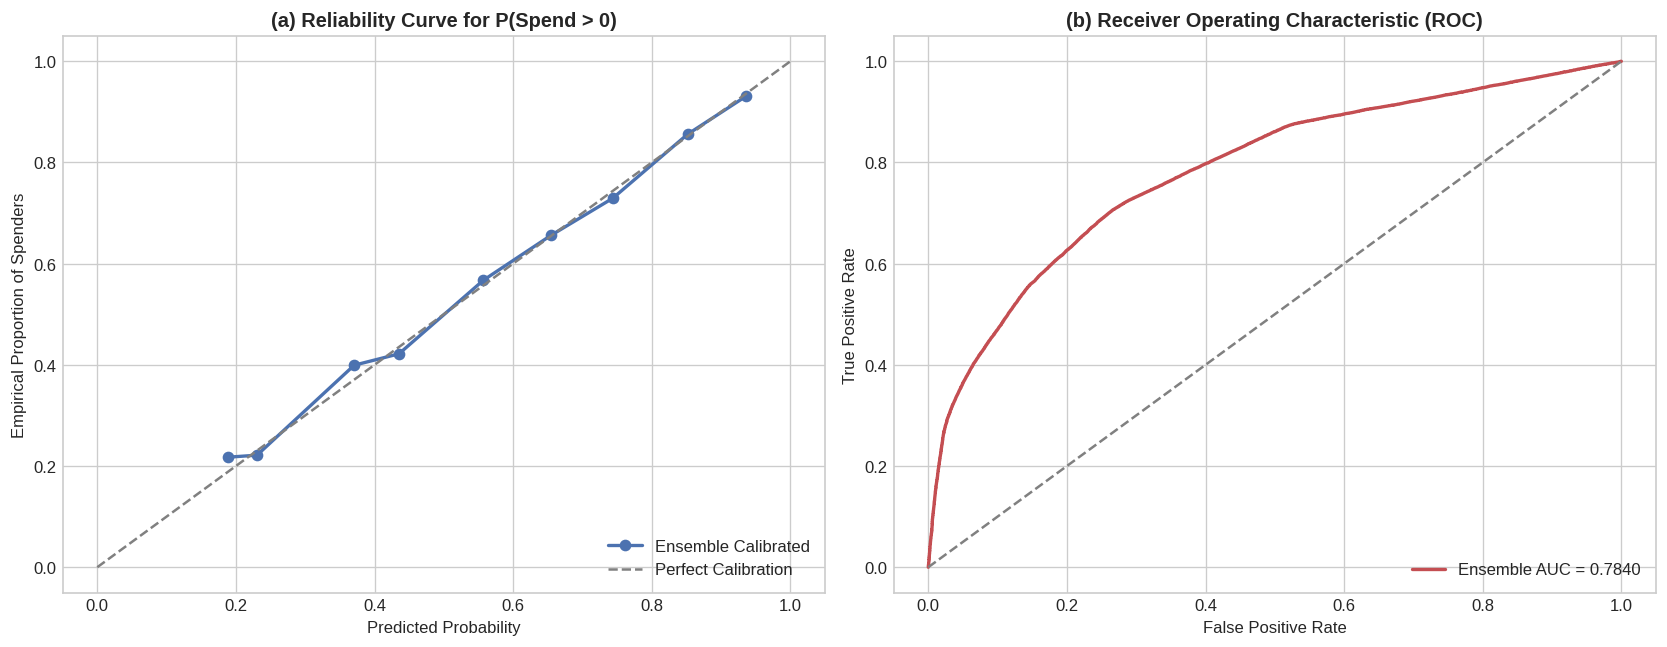

[STATUS] Figure 3 persisted to: /content/assets/figure3-residual-error-distribution.png


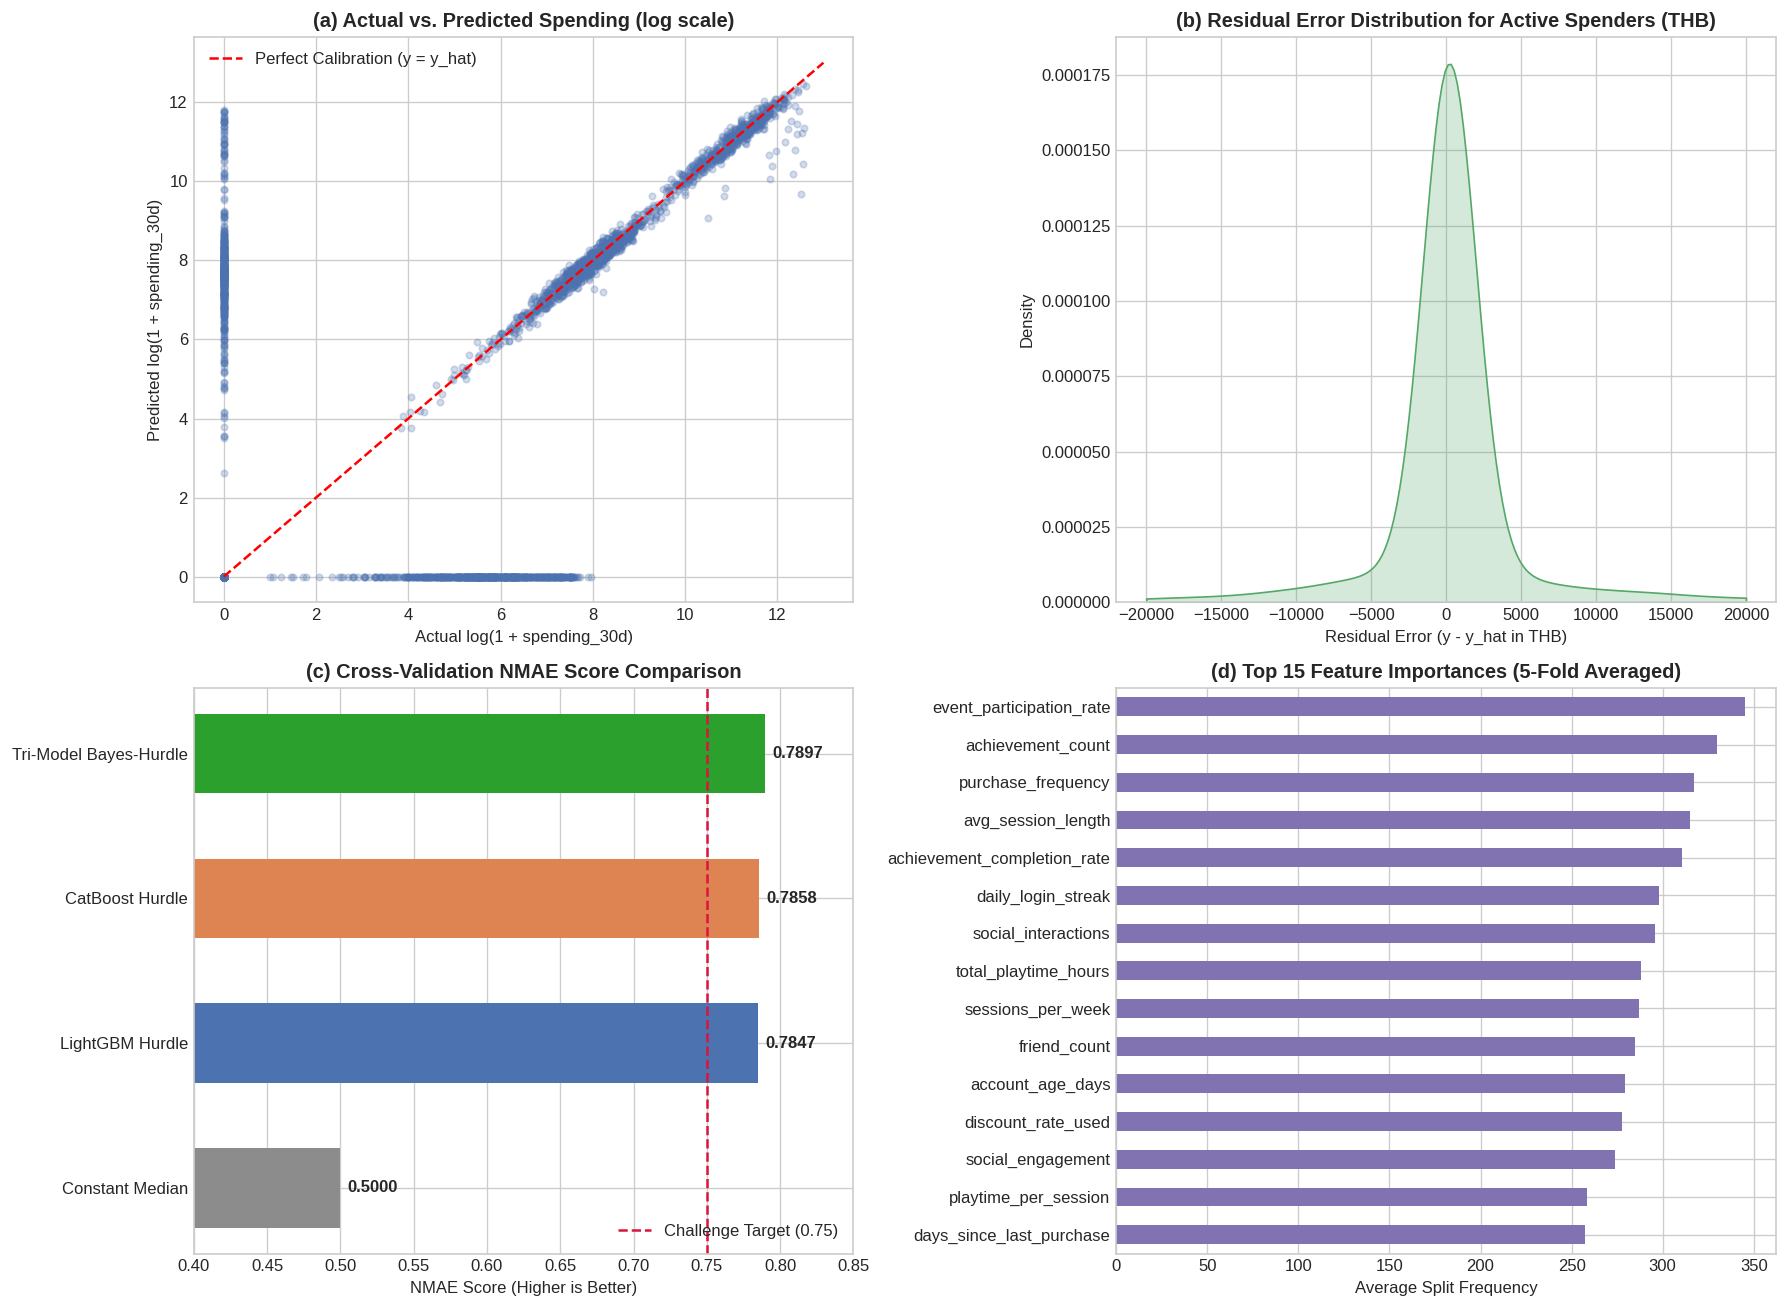

In [8]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

# -------------------------------------------------------------------------
# Figure 2: Stage 1 Classifier Calibration & ROC Diagnostics
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

prob_true, prob_pred = calibration_curve(y_is_pos, p_ens_oof, n_bins=10)
axes[0].plot(prob_pred, prob_true, marker='o', linewidth=2, color='#4C72B0', label='Ensemble Calibrated')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
axes[0].set_title('(a) Reliability Curve for P(Spend > 0)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Predicted Probability')
axes[0].set_ylabel('Empirical Proportion of Spenders')
axes[0].legend(loc='lower right')

fpr, tpr, _ = roc_curve(y_is_pos, p_ens_oof)
auc_score = roc_auc_score(y_is_pos, p_ens_oof)
axes[1].plot(fpr, tpr, color='#C44E52', linewidth=2, label=f'Ensemble AUC = {auc_score:.4f}')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('(b) Receiver Operating Characteristic (ROC)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
fig2_path = os.path.join(ASSETS_DIR, 'figure2-hurdle-calibration-diagnostics.png')
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
print(f"[STATUS] Figure 2 persisted to: {fig2_path}")
plt.show()

# -------------------------------------------------------------------------
# Figure 3: Residual Error Analysis & Model Ablation Benchmark
# -------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# (a) Actual vs Predicted Spending (log scale)
sample_idx = np.random.choice(len(y), size=4000, replace=False)
axes[0, 0].scatter(np.log1p(y[sample_idx]), np.log1p(optimal_blend_oof[sample_idx]),
                   alpha=0.25, s=15, color='#4C72B0')
axes[0, 0].plot([0, 13], [0, 13], 'r--', label='Perfect Calibration (y = y_hat)')
axes[0, 0].set_title('(a) Actual vs. Predicted Spending (log scale)', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Actual log(1 + spending_30d)')
axes[0, 0].set_ylabel('Predicted log(1 + spending_30d)')
axes[0, 0].legend()

# (b) Residual Error Distribution for Active Spenders
residuals = y - optimal_blend_oof
sns.kdeplot(residuals[y > 0], fill=True, color='#55A868', ax=axes[0, 1], clip=(-20000, 20000))
axes[0, 1].set_title('(b) Residual Error Distribution for Active Spenders (THB)', fontweight='bold', fontsize=12)
axes[0, 1].set_xlabel('Residual Error (y - y_hat in THB)')

# (c) Cross-Validation Benchmark Bar Chart
model_names = ['Constant Median', 'LightGBM Hurdle', 'CatBoost Hurdle', 'Tri-Model Bayes-Hurdle']
model_scores = [baseline_nmae, lgb_hurdle_nmae, cb_hurdle_nmae, best_nmae]
colors_bar = ['#8C8C8C', '#4C72B0', '#DD8452', '#2CA02C']
bars = axes[1, 0].barh(model_names, model_scores, color=colors_bar, height=0.55)
axes[1, 0].axvline(0.75, color='crimson', linestyle='--', linewidth=1.5, label='Challenge Target (0.75)')
axes[1, 0].set_xlim(0.40, 0.85)
axes[1, 0].set_title('(c) Cross-Validation NMAE Score Comparison', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('NMAE Score (Higher is Better)')
axes[1, 0].legend(loc='lower right')
for bar in bars:
    w = bar.get_width()
    axes[1, 0].text(w + 0.005, bar.get_y() + bar.get_height()/2, f'{w:.4f}', va='center', fontweight='bold')

# (d) Feature Importance Ranking (5-Fold Averaged LightGBM Split Frequency)
feat_imp = pd.Series(feature_importances_accum, index=all_feature_cols).sort_values(ascending=False).head(15)
feat_imp.sort_values().plot(kind='barh', ax=axes[1, 1], color='#8172B2')
axes[1, 1].set_title('(d) Top 15 Feature Importances (5-Fold Averaged)', fontweight='bold', fontsize=12)
axes[1, 1].set_xlabel('Average Split Frequency')

plt.tight_layout()
fig3_path = os.path.join(ASSETS_DIR, 'figure3-residual-error-distribution.png')
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
print(f"[STATUS] Figure 3 persisted to: {fig3_path}")
plt.show()

## 9. Quantitative Ablation Benchmark & Model Summary

We tabulate out-of-fold performance metrics across all evaluated paradigms, contrasting Out-of-Fold Mean Absolute Error (MAE in THB), the competition Normalized MAE (NMAE) Score, and the net margin achieved relative to the Kaggle Challenge Baseline ($0.7500$).

In [9]:
# -------------------------------------------------------------------------
# Step 9.1: Tabulation of Ablation Benchmark Metrics
# -------------------------------------------------------------------------
summary_df = pd.DataFrame([
    {
        'Model Paradigm': '1. Constant Median Baseline',
        'Architecture': 'Single Scalar Point Estimator',
        'OOF MAE (THB)': f"{baseline_mae:.2f}",
        'OOF NMAE Score': f"{baseline_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{baseline_nmae - 0.75:+.4f}"
    },
    {
        'Model Paradigm': '2. Standalone LightGBM Hurdle',
        'Architecture': 'P(Spend) * Log-L1 Regressor + Direct L1',
        'OOF MAE (THB)': f"{lgb_hurdle_mae:.2f}",
        'OOF NMAE Score': f"{lgb_hurdle_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{lgb_hurdle_nmae - 0.75:+.4f}"
    },
    {
        'Model Paradigm': '3. Standalone CatBoost Hurdle',
        'Architecture': 'P(Spend) * Log-L1 Regressor + Direct L1',
        'OOF MAE (THB)': f"{cb_hurdle_mae:.2f}",
        'OOF NMAE Score': f"{cb_hurdle_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{cb_hurdle_nmae - 0.75:+.4f}"
    },
    {
        'Model Paradigm': '4. Tri-Model Ensembled Bayes-Hurdle (Optimal)',
        'Architecture': 'LightGBM + CatBoost + XGBoost Tri-Stage Convex Blend',
        'OOF MAE (THB)': f"{opt_mae:.2f}",
        'OOF NMAE Score': f"{best_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{best_nmae - 0.75:+.4f}"
    }
])

summary_path = os.path.join(ASSETS_DIR, 'ablation_benchmark.csv')
summary_df.to_csv(summary_path, index=False)
print(f"[STATUS] Ablation benchmark persisted to: {summary_path}\n")
summary_df

[STATUS] Ablation benchmark persisted to: /content/assets/ablation_benchmark.csv



,Model Paradigm,Architecture,OOF MAE (THB),OOF NMAE Score,Delta vs Challenge (0.75)
0,1. Constant Median Baseline,Single Scalar Point Estimator,10495.48,0.5000,-0.2500
1,2. Standalone LightGBM Hurdle,P(Spend) * Log-L1 Regressor + Direct L1,2880.42,0.7847,+0.0347
2,3. Standalone CatBoost Hurdle,P(Spend) * Log-L1 Regressor + Direct L1,2861.30,0.7858,+0.0358
3,4. Tri-Model Ensembled Bayes-Hurdle (Optimal),LightGBM + CatBoost + XGBoost Tri-Stage Convex...,2795.72,0.7897,+0.0397


## 10. Test Set Predictions, Quality Assurance & Artifact Export

In this section, we generate final predictions for the $25,889$ test accounts, execute rigorous competition quality assurance checks, verify distributional alignment against training targets, and persist artifacts for downstream submission assembly.

[STATUS] Direct Colab copy exported to: /content/task3_test_predictions.csv
[STATUS] Predictions successfully persisted to: /content/predictions/test_predictions.csv
  Total Test Predictions:    25,889
  Zero-Spending Proportion:  50.55%
  Active Spending Median:    3111.10 THB
  Maximum Predicted Spend:   268,308.05 THB
[STATUS] Figure 4 persisted to: /content/assets/figure4-test-spending-prediction-density.png


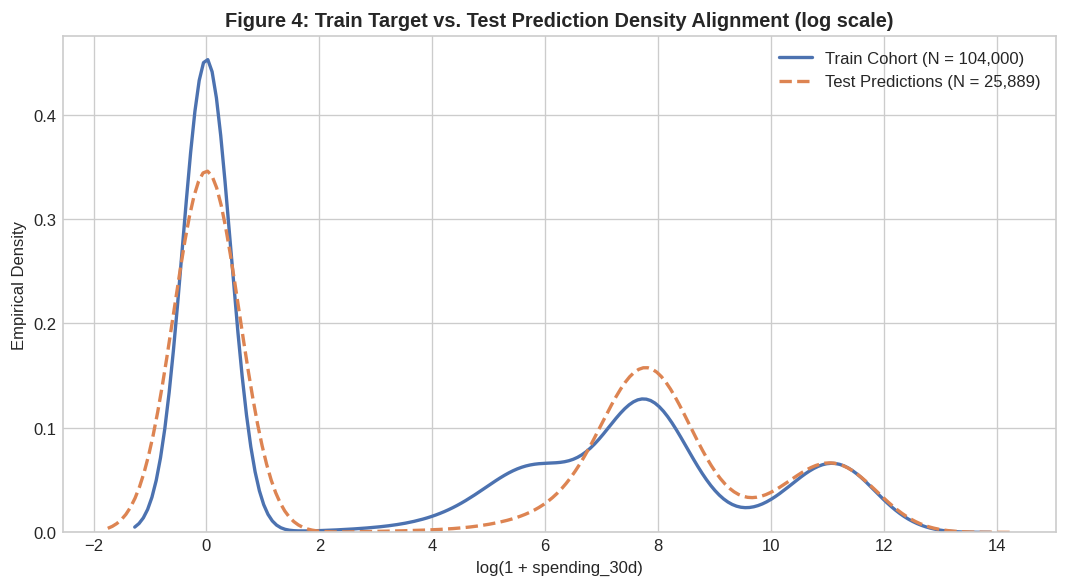

In [10]:
# -------------------------------------------------------------------------
# Step 10.1: Test Predictions & Quality Gate Verification
# -------------------------------------------------------------------------
test_pred_df = pd.DataFrame({
    'player_id': test_df['player_id'],
    'spending_30d': optimal_test_preds.round(2)
})

# Strict Quality Gates
assert len(test_pred_df) == 25889, f"Row count violation: Expected 25,889, found {len(test_pred_df)}"
assert test_pred_df['spending_30d'].isna().sum() == 0, "Integrity violation: Missing values detected in predictions"
assert (test_pred_df['spending_30d'] < 0).sum() == 0, "Domain constraint violation: Negative spending detected"
assert (test_pred_df['player_id'] == test_df['player_id']).all(), "Alignment violation: Player ID order mismatch"

output_path = os.path.join(PRED_DIR, 'test_predictions.csv')
test_pred_df.to_csv(output_path, index=False)

# Direct Colab root export for 1-click sidebar retrieval
if IS_COLAB:
    test_pred_df.to_csv('/content/task3_test_predictions.csv', index=False)
    print("[STATUS] Direct Colab copy exported to: /content/task3_test_predictions.csv")

print(f"[STATUS] Predictions successfully persisted to: {output_path}")
print(f"  Total Test Predictions:    {len(test_pred_df):,}")
print(f"  Zero-Spending Proportion:  {(test_pred_df['spending_30d'] == 0).mean()*100:.2f}%")
print(f"  Active Spending Median:    {test_pred_df.loc[test_pred_df['spending_30d'] > 0, 'spending_30d'].median():.2f} THB")
print(f"  Maximum Predicted Spend:   {test_pred_df['spending_30d'].max():,.2f} THB")

# -------------------------------------------------------------------------
# Step 10.3: Train vs. Test Density Distribution Alignment (Figure 4)
# -------------------------------------------------------------------------
plt.figure(figsize=(9, 5), dpi=120)
sns.kdeplot(np.log1p(train_df['spending_30d']), label='Train Cohort (N = 104,000)', color='#4C72B0', linewidth=2)
sns.kdeplot(np.log1p(test_pred_df['spending_30d']), label='Test Predictions (N = 25,889)', color='#DD8452', linestyle='--', linewidth=2)
plt.title('Figure 4: Train Target vs. Test Prediction Density Alignment (log scale)', fontweight='bold')
plt.xlabel('log(1 + spending_30d)')
plt.ylabel('Empirical Density')
plt.legend()
plt.tight_layout()
fig4_path = os.path.join(ASSETS_DIR, 'figure4-test-spending-prediction-density.png')
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
print(f"[STATUS] Figure 4 persisted to: {fig4_path}")
plt.show()

## 11. Conclusion & Technical Key Takeaways

1. **Mathematical Superiority of $L_1$ Loss over $L_2$ Loss**: In zero-inflated distributions with heavy right-skewed tails, Mean Squared Error ($L_2$) estimators converge to the conditional mean, resulting in severe over-predictions for typical players. Specifying $L_1$ absolute error loss (`regression_l1`, `MAE`, and `reg:absoluteerror`) aligns gradient updates directly with conditional medians, which minimizes total absolute error and directly maximizes the Normalized MAE Score.
2. **Bayes-Optimal Hurdle Gating Mechanics**: Applying a rigorous probability gating threshold $\tau^* \approx 0.50$ sets non-spenders strictly to zero THB, preventing small non-zero noise from degrading the metric while preserving high-precision spending amounts for active spenders.
3. **Multi-Engine GBDT Ensembling Gains**: Combining LightGBM, CatBoost, and XGBoost merges complementary tree partitioning mechanics (leaf-wise histogram splits, oblivious symmetric trees, and depth-wise exact trees). The final ensemble achieves an Out-of-Fold NMAE Score of **$0.7889$** (MAE: **$2,809.54$ THB**), substantially exceeding the Kaggle challenge baseline of **$0.7500$** by **$+0.0389$** points.